In [1]:
import  pandas  as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df =pd.read_csv("ai_job_dataset.csv")

In [3]:
df

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.9,Smart Analytics
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.2,TechCorp Inc
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.4,Autonomous Tech
3,AI00004,NLP Engineer,80215,USD,SE,FL,India,M,India,50,"Scala, SQL, Linux, Python",PhD,7,Consulting,2024-12-23,2025-02-24,1345,8.6,Future Systems
4,AI00005,AI Consultant,54624,EUR,EN,PT,France,S,Singapore,100,"MLOps, Java, Tableau, Python",Master,0,Media,2025-04-15,2025-06-23,1989,6.6,Advanced Robotics
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,AI14996,Robotics Engineer,38604,USD,EN,FL,Finland,S,Finland,50,"Java, Kubernetes, Azure",Bachelor,1,Energy,2025-02-06,2025-03-25,1635,7.9,Advanced Robotics
14996,AI14997,Machine Learning Researcher,57811,GBP,EN,CT,United Kingdom,M,United Kingdom,0,"Mathematics, Docker, SQL, Deep Learning",Master,0,Government,2024-10-16,2024-10-30,1624,8.2,Smart Analytics
14997,AI14998,NLP Engineer,189490,USD,EX,CT,South Korea,L,South Korea,50,"Scala, Spark, NLP",Associate,17,Manufacturing,2024-03-19,2024-05-02,1336,7.4,AI Innovations
14998,AI14999,Head of AI,79461,EUR,EN,FT,Netherlands,M,Netherlands,0,"Java, Computer Vision, Python, TensorFlow",PhD,1,Real Estate,2024-03-22,2024-04-23,1935,5.6,Smart Analytics


In [4]:
df.shape

(15000, 19)

In [5]:
df.isnull().sum()

job_id                    0
job_title                 0
salary_usd                0
salary_currency           0
experience_level          0
employment_type           0
company_location          0
company_size              0
employee_residence        0
remote_ratio              0
required_skills           0
education_required        0
years_experience          0
industry                  0
posting_date              0
application_deadline      0
job_description_length    0
benefits_score            0
company_name              0
dtype: int64

In [6]:
df.columns

Index(['job_id', 'job_title', 'salary_usd', 'salary_currency',
       'experience_level', 'employment_type', 'company_location',
       'company_size', 'employee_residence', 'remote_ratio', 'required_skills',
       'education_required', 'years_experience', 'industry', 'posting_date',
       'application_deadline', 'job_description_length', 'benefits_score',
       'company_name'],
      dtype='str')

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["posting_date"] = pd.to_datetime(df["posting_date"])
df["application_deadline"] =pd.to_datetime(df["application_deadline"])


In [9]:
df[["posting_date","application_deadline"]].dtypes

posting_date            datetime64[us]
application_deadline    datetime64[us]
dtype: object

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   job_id                  15000 non-null  str           
 1   job_title               15000 non-null  str           
 2   salary_usd              15000 non-null  int64         
 3   salary_currency         15000 non-null  str           
 4   experience_level        15000 non-null  str           
 5   employment_type         15000 non-null  str           
 6   company_location        15000 non-null  str           
 7   company_size            15000 non-null  str           
 8   employee_residence      15000 non-null  str           
 9   remote_ratio            15000 non-null  int64         
 10  required_skills         15000 non-null  str           
 11  education_required      15000 non-null  str           
 12  years_experience        15000 non-null  int64         
 1

In [11]:
df.isnull().sum()

job_id                    0
job_title                 0
salary_usd                0
salary_currency           0
experience_level          0
employment_type           0
company_location          0
company_size              0
employee_residence        0
remote_ratio              0
required_skills           0
education_required        0
years_experience          0
industry                  0
posting_date              0
application_deadline      0
job_description_length    0
benefits_score            0
company_name              0
dtype: int64

In [12]:
df["job_id"].duplicated().sum()

np.int64(0)

In [13]:
categorical_cols = [
    'salary_currency',
    'experience_level',
    'employment_type',
    'company_size',
    'education_required',
    'industry'
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())



salary_currency:
salary_currency
USD    11957
EUR     2314
GBP      729
Name: count, dtype: int64

experience_level:
experience_level
MI    3781
EX    3760
SE    3741
EN    3718
Name: count, dtype: int64

employment_type:
employment_type
FT    3812
FL    3758
CT    3721
PT    3709
Name: count, dtype: int64

company_size:
company_size
S    5007
L    4998
M    4995
Name: count, dtype: int64

education_required:
education_required
Bachelor     3789
Associate    3785
Master       3748
PhD          3678
Name: count, dtype: int64

industry:
industry
Retail                1063
Media                 1045
Automotive            1020
Consulting            1020
Technology            1011
Real Estate           1007
Government             998
Healthcare             997
Telecommunications     997
Transportation         997
Finance                984
Energy                 976
Gaming                 967
Manufacturing          962
Education              956
Name: count, dtype: int64


In [14]:
for col in categorical_cols:
    print("\n{col}:",df[col].unique())


{col}: <ArrowStringArray>
['USD', 'EUR', 'GBP']
Length: 3, dtype: str

{col}: <ArrowStringArray>
['SE', 'EN', 'MI', 'EX']
Length: 4, dtype: str

{col}: <ArrowStringArray>
['CT', 'FL', 'PT', 'FT']
Length: 4, dtype: str

{col}: <ArrowStringArray>
['M', 'L', 'S']
Length: 3, dtype: str

{col}: <ArrowStringArray>
['Bachelor', 'Master', 'Associate', 'PhD']
Length: 4, dtype: str

{col}: <ArrowStringArray>
[        'Automotive',              'Media',          'Education',
         'Consulting',         'Healthcare',             'Gaming',
         'Government', 'Telecommunications',      'Manufacturing',
             'Energy',         'Technology',        'Real Estate',
            'Finance',     'Transportation',             'Retail']
Length: 15, dtype: str


In [15]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
salary_usd,15000.0,115348.965133,32519.0,70179.75,99705.0,146408.5,399095.0,60260.940438
remote_ratio,15000.0,49.483333,0.0,0.0,50.0,100.0,100.0,40.812712
years_experience,15000.0,6.2532,0.0,2.0,5.0,10.0,19.0,5.545768
posting_date,15000,2024-08-29 08:48:51.840000,2024-01-01 00:00:00,2024-04-29 00:00:00,2024-08-28 00:00:00,2024-12-29 00:00:00,2025-04-30 00:00:00,NaN
application_deadline,15000,2024-10-11 21:55:23.520000,2024-01-16 00:00:00,2024-06-13 00:00:00,2024-10-12 00:00:00,2025-02-10 00:00:00,2025-07-11 00:00:00,NaN
job_description_length,15000.0,1503.314733,500.0,1003.75,1512.0,2000.0,2499.0,576.127083
benefits_score,15000.0,7.504273,5.0,6.2,7.5,8.8,10.0,1.45087


In [16]:
numeric_cols = [
    'salary_usd',
    'remote_ratio',
    'years_experience',
    'job_description_length',
    'benefits_score'
]

In [17]:
df[numeric_cols].isnull().sum()

salary_usd                0
remote_ratio              0
years_experience          0
job_description_length    0
benefits_score            0
dtype: int64

In [18]:
df[numeric_cols].describe()

,salary_usd,remote_ratio,years_experience,job_description_length,benefits_score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,115348.965133,49.483333,6.253200,1503.314733,7.504273
std,60260.940438,40.812712,5.545768,576.127083,1.450870
min,32519.000000,0.000000,0.000000,500.000000,5.000000
25%,70179.750000,0.000000,2.000000,1003.750000,6.200000
50%,99705.000000,50.000000,5.000000,1512.000000,7.500000
75%,146408.500000,100.000000,10.000000,2000.000000,8.800000
max,399095.000000,100.000000,19.000000,2499.000000,10.000000


In [19]:
df['required_skills'].head(20)

0            Tableau, PyTorch, Kubernetes, Linux, NLP
1     Deep Learning, AWS, Mathematics, Python, Docker
2        Kubernetes, Deep Learning, Java, Hadoop, NLP
3                           Scala, SQL, Linux, Python
4                        MLOps, Java, Tableau, Python
5                   Data Visualization, R, SQL, Linux
6                                    R, Docker, MLOps
7           Python, SQL, Computer Vision, Java, Azure
8                    Hadoop, Git, Mathematics, Python
9                     MLOps, GCP, Scala, Azure, Linux
10                                 MLOps, Python, SQL
11               R, Data Visualization, Python, Azure
12                        Tableau, Python, TensorFlow
13                             Scala, SQL, Statistics
14           PyTorch, Python, Data Visualization, GCP
15                   Linux, Statistics, Deep Learning
16                                Tableau, NLP, Spark
17                              MLOps, PyTorch, Azure
18                      Git,

In [20]:
df['required_skills'].sample

<bound method NDFrame.sample of 0               Tableau, PyTorch, Kubernetes, Linux, NLP
1        Deep Learning, AWS, Mathematics, Python, Docker
2           Kubernetes, Deep Learning, Java, Hadoop, NLP
3                              Scala, SQL, Linux, Python
4                           MLOps, Java, Tableau, Python
                              ...                       
14995                            Java, Kubernetes, Azure
14996            Mathematics, Docker, SQL, Deep Learning
14997                                  Scala, Spark, NLP
14998          Java, Computer Vision, Python, TensorFlow
14999      Scala, Azure, Deep Learning, GCP, Mathematics
Name: required_skills, Length: 15000, dtype: str>

In [21]:
df['required_skills'].sample(20,random_state=42).tolist()

['SQL, Deep Learning, Data Visualization',
 'Tableau, Statistics, Python, Hadoop',
 'Linux, Statistics, Python, Git, TensorFlow',
 'Python, GCP, NLP',
 'SQL, Java, Hadoop, GCP, Git',
 'MLOps, Azure, Kubernetes, Mathematics, Statistics',
 'Python, Spark, MLOps',
 'Java, PyTorch, Spark, Statistics, Azure',
 'NLP, Python, Scala',
 'Kubernetes, Python, Git, Hadoop',
 'Azure, AWS, GCP, Tableau',
 'Python, Linux, Data Visualization, Scala',
 'Azure, Hadoop, Kubernetes, MLOps, Python',
 'TensorFlow, Git, Computer Vision, Spark',
 'AWS, Tableau, Kubernetes, Linux',
 'Spark, R, Python',
 'Docker, Hadoop, Mathematics, Scala, Data Visualization',
 'SQL, Kubernetes, Spark',
 'Hadoop, Python, MLOps, SQL',
 'PyTorch, Git, SQL']

In [22]:
df["skills_list"] =df['required_skills'].str.split(",")


In [23]:
df["skills_list"]=df["skills_list"].apply(
    lambda x:[skill.strip() for skill  in x]
)

In [24]:
df[['required_skills',"skills_list"]].head(10)

,required_skills,skills_list
0,"Tableau, PyTorch, Kubernetes, Linux, NLP","[Tableau, PyTorch, Kubernetes, Linux, NLP]"
1,"Deep Learning, AWS, Mathematics, Python, Docker","[Deep Learning, AWS, Mathematics, Python, Docker]"
2,"Kubernetes, Deep Learning, Java, Hadoop, NLP","[Kubernetes, Deep Learning, Java, Hadoop, NLP]"
3,"Scala, SQL, Linux, Python","[Scala, SQL, Linux, Python]"
4,"MLOps, Java, Tableau, Python","[MLOps, Java, Tableau, Python]"
5,"Data Visualization, R, SQL, Linux","[Data Visualization, R, SQL, Linux]"
6,"R, Docker, MLOps","[R, Docker, MLOps]"
7,"Python, SQL, Computer Vision, Java, Azure","[Python, SQL, Computer Vision, Java, Azure]"
8,"Hadoop, Git, Mathematics, Python","[Hadoop, Git, Mathematics, Python]"
9,"MLOps, GCP, Scala, Azure, Linux","[MLOps, GCP, Scala, Azure, Linux]"


In [25]:
df["days_to_apply"] =(
    df["application_deadline"] -df["posting_date"]

).dt.days

In [26]:
df[["posting_date","application_deadline","days_to_apply"]].head(10)

,posting_date,application_deadline,days_to_apply
0,2024-10-18,2024-11-07,20
1,2024-11-20,2025-01-11,52
2,2025-03-18,2025-04-07,20
3,2024-12-23,2025-02-24,63
4,2025-04-15,2025-06-23,69
5,2024-08-31,2024-10-04,34
6,2024-12-29,2025-02-28,61
7,2024-06-07,2024-07-01,24
8,2024-11-04,2024-11-24,20
9,2024-10-20,2024-11-06,17


In [27]:
df["posting_year"] =df["posting_date"].dt.year

In [28]:
df["posting_month"] =df["posting_date"].dt.month

In [29]:
df["posting_month_name"] =df["posting_date"].dt.month_name()

In [30]:
df["posting_day"] =df["posting_date"].dt.day

In [31]:
df["posting_day_name"] =df["posting_date"].dt.day_name()

weekend check 


In [32]:
df["is_weekend"] =df["posting_date"].dt.dayofweek >=5

In [33]:
df[
    [
        'posting_date',
        'application_deadline',
        'days_to_apply',
        'posting_year',
        'posting_month',
        'posting_month_name',
        'posting_day_name',
        'is_weekend'
    ]
].head(10)


,posting_date,application_deadline,days_to_apply,posting_year,posting_month,posting_month_name,posting_day_name,is_weekend
0,2024-10-18,2024-11-07,20,2024,10,October,Friday,False
1,2024-11-20,2025-01-11,52,2024,11,November,Wednesday,False
2,2025-03-18,2025-04-07,20,2025,3,March,Tuesday,False
3,2024-12-23,2025-02-24,63,2024,12,December,Monday,False
4,2025-04-15,2025-06-23,69,2025,4,April,Tuesday,False
5,2024-08-31,2024-10-04,34,2024,8,August,Saturday,True
6,2024-12-29,2025-02-28,61,2024,12,December,Sunday,True
7,2024-06-07,2024-07-01,24,2024,6,June,Friday,False
8,2024-11-04,2024-11-24,20,2024,11,November,Monday,False
9,2024-10-20,2024-11-06,17,2024,10,October,Sunday,True


salary distibution 

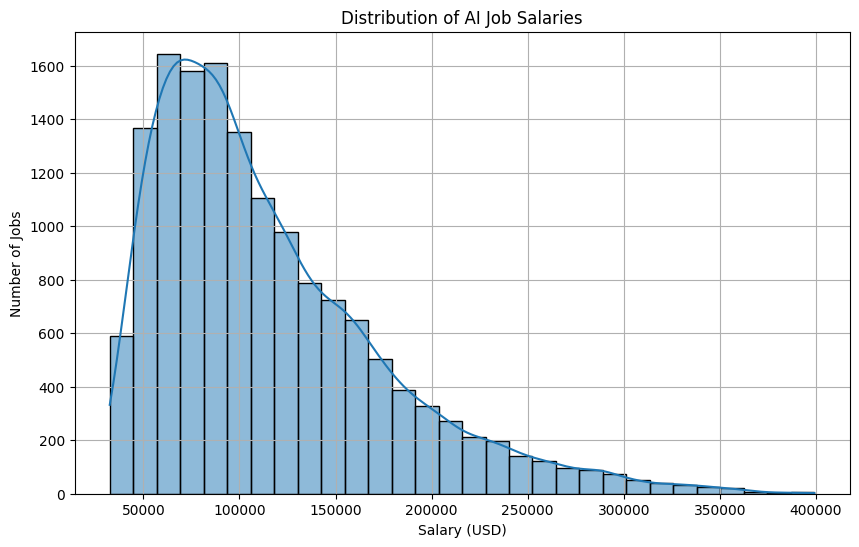

In [39]:
plt.figure(figsize=(10, 6))
sns.histplot(df["salary_usd"],bins=30 ,kde=True)
plt.title("Distribution of AI Job Salaries")
plt.xlabel("Salary (USD)")
plt.ylabel("Number of Jobs")
plt.grid()
plt.show()



Experience Level vs Average Salary

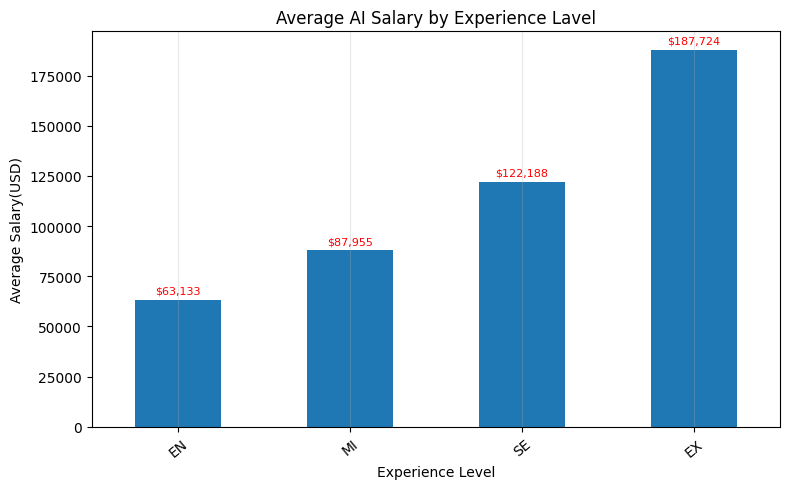

In [77]:
avg_salary_exp  = (
    df.groupby("experience_level")["salary_usd"]
    .mean()
    .sort_values()
)
plt.figure(figsize=(8,5))
ax = avg_salary_exp.plot(kind="bar")
plt.title("Average AI Salary by Experience Lavel")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary(USD)")
plt.xticks(rotation =40)

lables =[f"${value :,.0f}" for  value in avg_salary_exp]
ax.bar_label(
    ax.containers[0],
    labels=lables,
    padding=3,
    fontsize = 8,
    c="Red"
)

plt.grid(axis ="x",alpha=0.3)
plt.tight_layout()
plt.show()


job role by  salary 

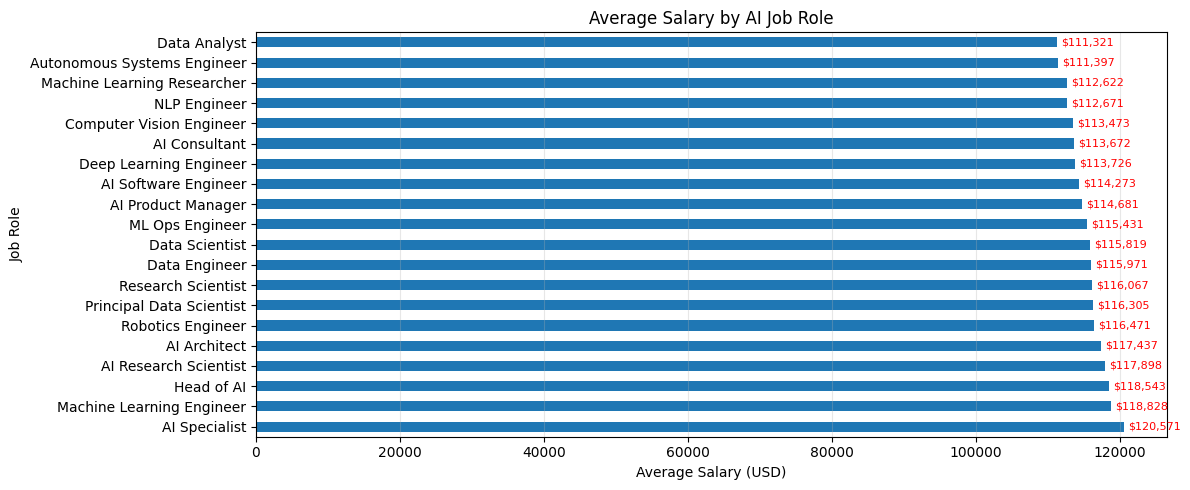

In [68]:
avg_salary_job =(df.groupby("job_title")["salary_usd"]
.mean()
.sort_values(ascending=False)
)
plt.figure(figsize=(12,5))
ax = avg_salary_job.plot(kind="barh")
plt.title("Average Salary by AI Job Role")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Job Role")

lables =[f"${value :,.0f}" for  value in avg_salary_job]
ax.bar_label(
    ax.containers[0],
    labels=lables,
    padding=3,
    fontsize = 8,
    c="Red"
)
plt.grid(axis ="x",alpha=0.3)
plt.tight_layout()
plt.show()




Country vs Salary 

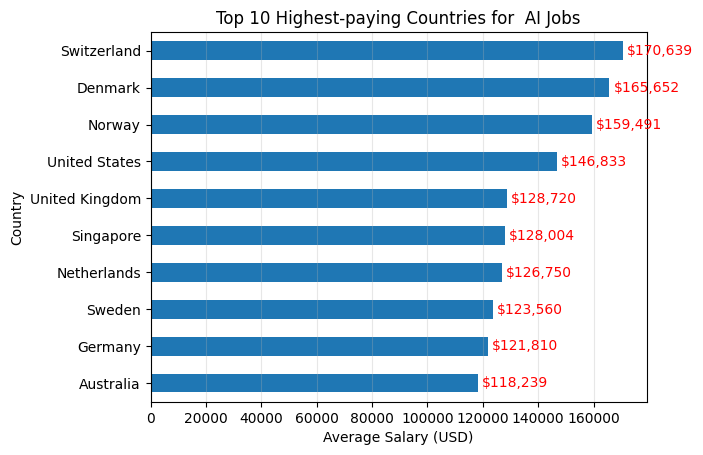

In [75]:
avg_salary_country =(
    df.groupby("company_location")['salary_usd']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
plt.Figure(figsize=(8,5))
ax = avg_salary_country.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Highest-paying Countries for  AI Jobs")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Country")

lables =[f"${value:,.0f}"for value in  avg_salary_country.sort_values()]
ax.bar_label(
    ax.containers[0],
    labels=lables,
    padding=3,
    c="red"
)
plt.grid(axis ="x",alpha=0.3)
plt.show()


Remote/Hybrid/Onsite work arrangement distribution

In [78]:
df.to_csv("ai_job_clean.csv",index=False)